# Note 05: 2D and 3D CUDA Indexing

So far, all of our CUDA kernels have used one-dimensional indexing.

For example:

```cpp
int i =
    blockIdx.x * blockDim.x
    + threadIdx.x;
```

This works naturally for data that can be thought of as a single long array:

```text
[0][1][2][3][4][5][6][7]...
```

But many real workloads are naturally multidimensional.

Examples include:

```text
matrices
images
feature maps
volumes
```

A matrix might look like:

```text
1  2  3  4
5  6  7  8
9 10 11 12
```

Instead of thinking only about:

```text
element 0
element 1
element 2
...
```

it is often easier to think in terms of:

```text
row
column
```

CUDA supports this directly.

Threads and blocks can have up to three dimensions:

```text
x
y
z
```

So instead of only using:

```cpp
threadIdx.x
blockIdx.x
```

we can also use:

```cpp
threadIdx.y
blockIdx.y

threadIdx.z
blockIdx.z
```

This allows the CUDA execution layout to match the shape of the data more naturally.

In this note, we will learn:

- how 2D thread blocks work
- how 2D grids work
- what `dim3` means
- how `threadIdx.x` and `threadIdx.y` work together
- how `blockIdx.x` and `blockIdx.y` identify blocks
- how to calculate global row and column indices
- how 2D matrix data is actually stored in linear memory
- how to convert `(row, column)` into a normal memory index
- how the same idea extends into 3D indexing

We will use matrix addition as the main example because it makes the mapping between CUDA threads and 2D data easy to see.

The main idea is:

```text
1D CUDA:

thread
  ↓
one array index


2D CUDA:

thread
  ↓
(row, column)


3D CUDA:

thread
  ↓
(x, y, z)
```

The computation itself is still simple.

The new part is learning how CUDA maps multidimensional threads onto multidimensional data.

# 1. A Thread Index Is Actually 3D

Until now, we have only used:

```cpp
threadIdx.x
```

But CUDA gives every thread three possible coordinates:

```cpp
threadIdx.x
threadIdx.y
threadIdx.z
```

For a one-dimensional kernel, we only use:

```text
x
```

For a two-dimensional kernel, we usually use:

```text
x and y
```

For a three-dimensional kernel, we can use:

```text
x, y and z
```

For now, we will ignore `z` and focus on 2D indexing.

---

# 2. A 2D Thread Block

Imagine a block containing:

```text
4 threads in x
3 threads in y
```

That gives:

```text
4 × 3 = 12 threads
```

inside one block.

![2D CUDA thread block](assets/2d_cuda_indexing_infographic.png)

Each thread now has two coordinates.

For example, the highlighted thread might have:

```cpp
threadIdx.x = 2;
threadIdx.y = 1;
```

A useful mental model is:

```text
x → column
y → row
```

So:

```text
threadIdx.x = 2
threadIdx.y = 1
```

means:

```text
column 2
row 1
```

Visually:

```text
          x

       0   1   2   3

y = 0  T   T   T   T
y = 1  T   T   X   T
y = 2  T   T   T   T
```

`X` represents the thread:

```text
(x = 2, y = 1)
```

---

# 3. `blockDim` Is Also Multidimensional

Previously we used:

```cpp
blockDim.x
```

to ask:

> How many threads are in this block along the x direction?

For a 2D block we also have:

```cpp
blockDim.y
```

So if the block contains:

```text
4 threads in x
3 threads in y
```

then:

```cpp
blockDim.x = 4;
blockDim.y = 3;
```

The total number of threads in the block is:

```text
blockDim.x × blockDim.y

= 4 × 3

= 12 threads
```

---

# 4. Creating a 2D Block with `dim3`

CUDA provides a type called:

```cpp
dim3
```

which is used to describe dimensions.

For example:

```cpp
dim3 threads_per_block(4, 3);
```

means:

```text
x = 4
y = 3
z = 1
```

The third dimension defaults to `1` if we do not provide it.

So:

```cpp
dim3 threads_per_block(4, 3);
```

creates the shape:

```text
4 threads wide
3 threads tall
```

or:

```text
12 threads total
```

We can then use it in a kernel launch:

```cpp
kernel<<<blocks, threads_per_block>>>();
```

Instead of:

```cpp
kernel<<<blocks, 256>>>();
```

the second launch argument is now a multidimensional block shape.

---

# 5. Blocks Can Also Be 2D

Just like threads inside a block can have:

```text
x
y
```

blocks inside a grid can also have:

```text
x
y
```

A grid might look like:

```text
3 blocks wide
2 blocks tall
```

![2D CUDA grid of blocks](assets/2d_cuda_indexing_infographic.png)

A block can therefore have coordinates such as:

```cpp
blockIdx.x = 1;
blockIdx.y = 0;
```

So there are two levels of coordinates:

```text
GRID

blockIdx.x
blockIdx.y

        ↓

BLOCK

threadIdx.x
threadIdx.y
```

The block tells us which region of the data we are working on.

The thread tells us which position inside that region we are working on.

---

# 6. The 2D Global Index

In 1D we calculated:

```cpp
int i =
    blockIdx.x * blockDim.x
    + threadIdx.x;
```

In 2D we do the same thing independently for both dimensions.

Column:

```cpp
int col =
    blockIdx.x * blockDim.x
    + threadIdx.x;
```

Row:

```cpp
int row =
    blockIdx.y * blockDim.y
    + threadIdx.y;
```

So:

```text
col
```

tells us the global column,

and:

```text
row
```

tells us the global row.

This is simply the 2D version of the global thread ID we already learned.

---

# 7. What 3D Indexing Looks Like

The same idea extends to a third dimension.

A thread can have:

```cpp
threadIdx.x
threadIdx.y
threadIdx.z
```

and a block can have:

```cpp
blockIdx.x
blockIdx.y
blockIdx.z
```

![3D CUDA indexing](assets/3d_cuda_indexing_infographic.png)

The global coordinates become:

```cpp
int x =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int y =
    blockIdx.y * blockDim.y
    + threadIdx.y;

int z =
    blockIdx.z * blockDim.z
    + threadIdx.z;
```

This is useful for data that naturally has three dimensions, such as:

```text
3D volumes
voxel grids
scientific simulations
3D image data
```

For now, we will focus mainly on 2D indexing because it introduces the core idea clearly.

Once 2D indexing makes sense, 3D indexing is simply the same pattern with one more coordinate.

---

# Current Mental Model

```text
1D CUDA

thread
↓
one global index


2D CUDA

thread
↓
(row, column)


3D CUDA

thread
↓
(x, y, z)
```

The main idea has not changed.

Each thread still needs to answer:

> Which piece of data am I responsible for?

The only difference is that the answer can now contain more than one coordinate.

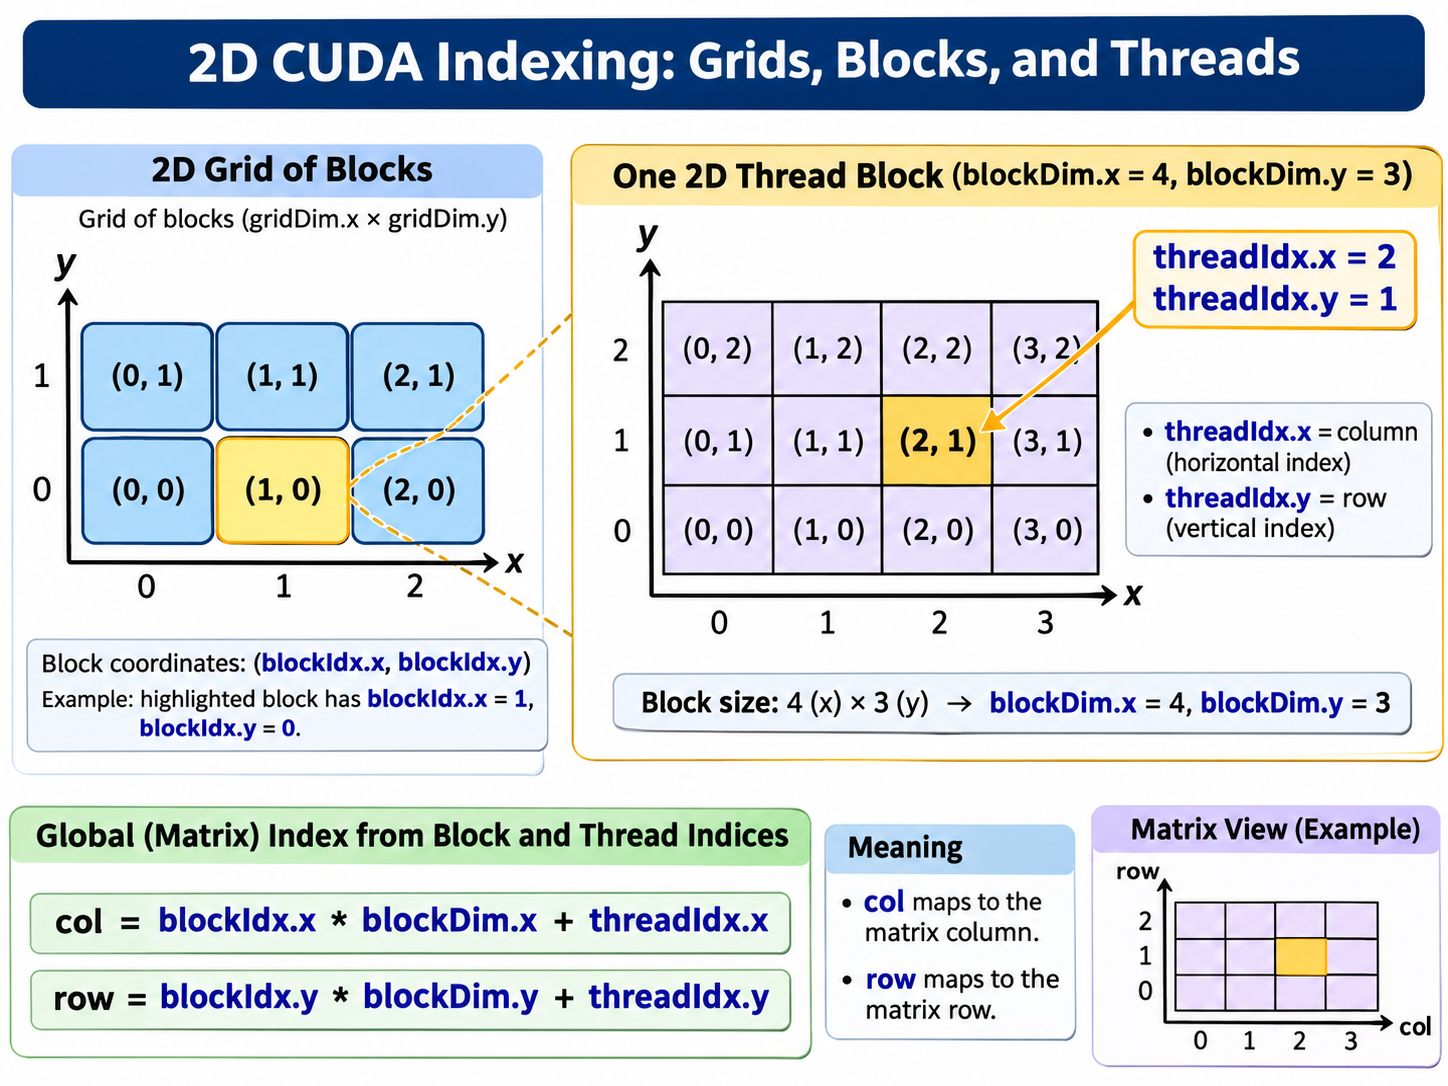

In [ ]:
from IPython.display import Image, display

display(
    Image(
        "/content/assets/2d_cuda_indexing_infographic.png",
        width=700
    )
)

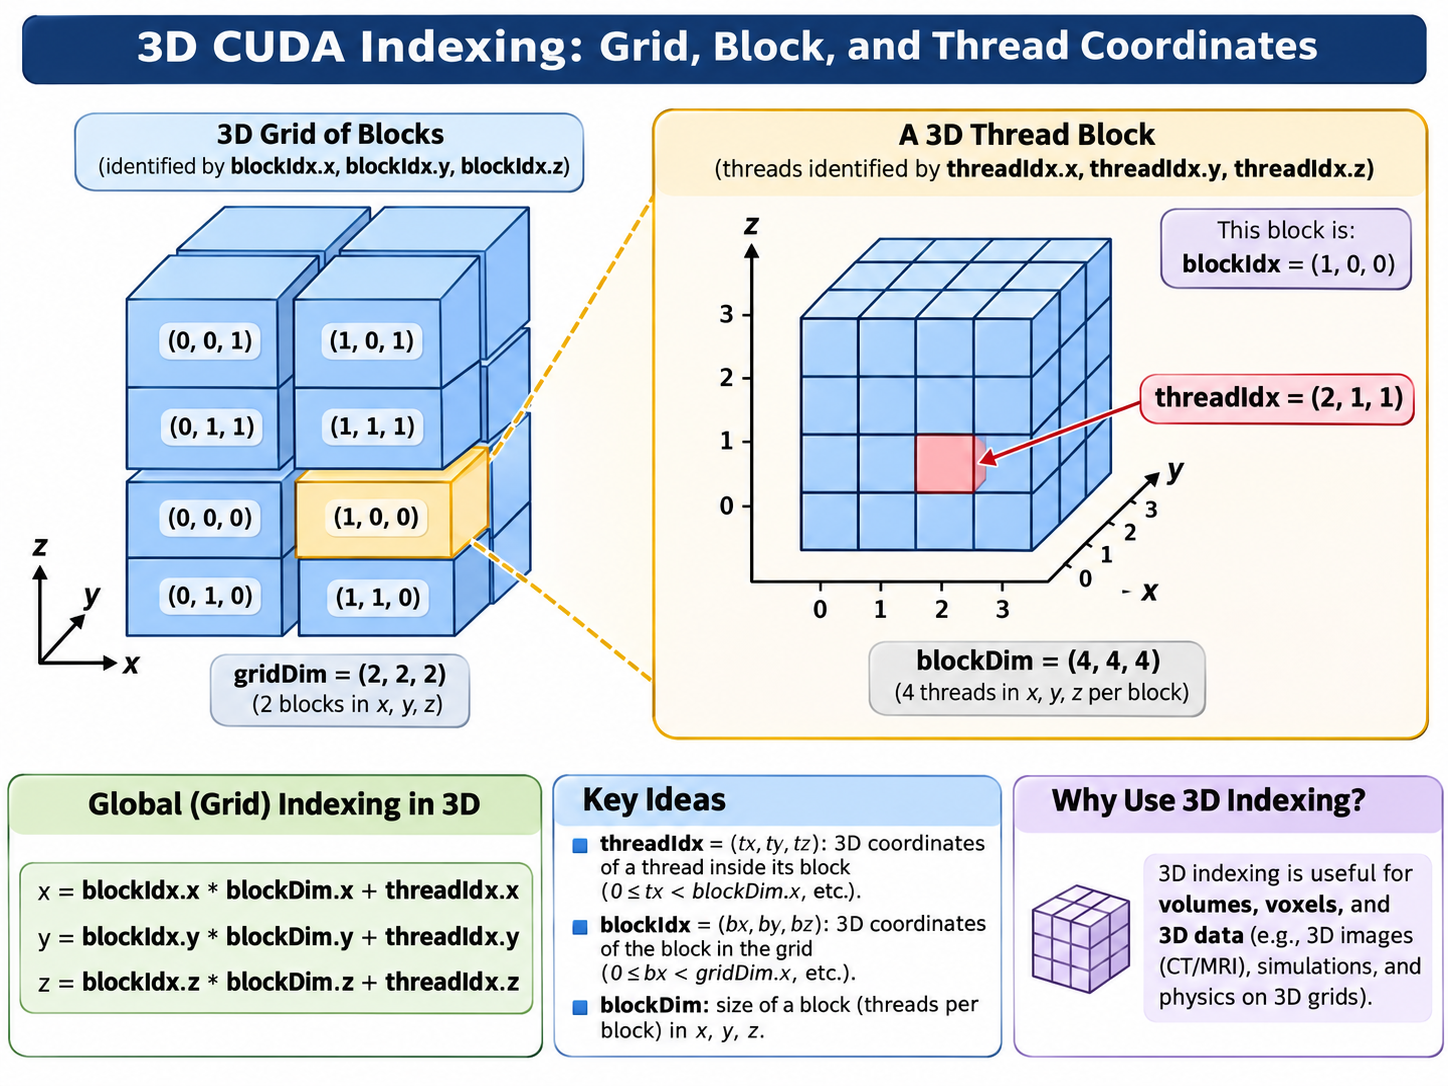

In [ ]:
display(
    Image(
        "/content/assets/3d_cuda_indexing_infographic.png",
        width=700
    )
)

# 8. How a 2D Matrix Is Stored in Memory

When we look at a matrix, we naturally think of rows and columns.

For example:

```text
1   2   3   4
5   6   7   8
9  10  11  12
```

This looks like a 2D structure:

```text
3 rows
4 columns
```

But GPU memory is still laid out as a linear sequence of values.

So the same matrix is stored like this:

```text
[1][2][3][4][5][6][7][8][9][10][11][12]
```

This means that once a CUDA thread calculates:

```cpp
int row =
    blockIdx.y * blockDim.y
    + threadIdx.y;

int col =
    blockIdx.x * blockDim.x
    + threadIdx.x;
```

we still need to convert:

```text
(row, col)
```

into one normal linear memory index.

---

## Converting `(row, col)` Into a Linear Index

For a matrix with:

```text
width = number of columns
```

the standard row-major indexing formula is:

```cpp
int index = row * width + col;
```

The idea is:

```text
skip all complete rows before this one
+
move to the correct column
```

---

## Example

Suppose the matrix is:

```text
1   2   3   4
5   6   7   8
9  10  11  12
```

The width is:

```text
4
```

Now consider:

```text
row = 2
col = 1
```

We calculate:

```text
index = row * width + col

index = 2 * 4 + 1

index = 9
```

So:

```text
matrix[2][1]
```

corresponds to:

```cpp
matrix[9]
```

in linear memory.

---

## Why This Works

Each row contains:

```text
width
```

elements.

So if:

```text
width = 4
```

then every row occupies four positions in memory.

The layout is:

```text
Row 0 → indices 0  1  2  3

Row 1 → indices 4  5  6  7

Row 2 → indices 8  9 10 11
```

To reach:

```text
row 2
```

we skip:

```text
2 * 4 = 8
```

elements.

Then to reach:

```text
column 1
```

we move one more position:

```text
8 + 1 = 9
```

So:

```text
(row = 2, col = 1)
```

maps to:

```text
index = 9
```

---

## Visual Mapping

```text
2D view

        col
        0   1   2   3

row 0   1   2   3   4
row 1   5   6   7   8
row 2   9  10  11  12
```

Linear memory:

```text
index:  0  1  2  3  4  5  6  7  8  9  10  11

value:  1  2  3  4  5  6  7  8  9 10  11  12
```

For:

```text
row = 2
col = 1
```

we get:

```text
index = 9
```

which contains:

```text
10
```

---

## Using This Inside a CUDA Kernel

A 2D CUDA kernel will usually calculate:

```cpp
int col =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int row =
    blockIdx.y * blockDim.y
    + threadIdx.y;
```

Then convert the 2D coordinate into a linear memory index:

```cpp
int index = row * width + col;
```

So the flow is:

```text
thread coordinates
      ↓
global row and column
      ↓
linear memory index
      ↓
access the actual element
```

For example:

```cpp
int col =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int row =
    blockIdx.y * blockDim.y
    + threadIdx.y;

int index =
    row * width + col;
```

Then the thread can access:

```cpp
matrix[index]
```

---

# Current Mental Model

CUDA lets us think in 2D:

```text
(row, col)
```

but the actual data still lives in linear memory.

So we need:

```text
(row, col)
      ↓
row * width + col
      ↓
linear index
```

The important formula is:

```cpp
index = row * width + col;
```

This is the bridge between:

```text
2D thread coordinates
```

and:

```text
1D memory
```

We will use this directly in the next section when we write our first 2D matrix-add kernel.

In [ ]:
#dry run code to make u understand

%%writefile matrix_index_dryrun.cu

#include <cstdio>
#include <cuda_runtime.h>

__global__ void print_matrix_indices(int rows, int cols) {

    int col =
        blockIdx.x * blockDim.x
        + threadIdx.x;

    int row =
        blockIdx.y * blockDim.y
        + threadIdx.y;

    if (row < rows && col < cols) {

        int index =
            row * cols + col;

        printf(
            "block(%d,%d) thread(%d,%d) -> row=%d col=%d index=%d\n",
            blockIdx.x,
            blockIdx.y,
            threadIdx.x,
            threadIdx.y,
            row,
            col,
            index
        );
    }
}

int main() {

    const int rows = 3;
    const int cols = 4;

    // 2 x 2 threads inside each block
    dim3 threads_per_block(2, 2);

    // Enough blocks to cover 4 columns and 3 rows
    dim3 blocks(
        (cols + threads_per_block.x - 1)
            / threads_per_block.x,

        (rows + threads_per_block.y - 1)
            / threads_per_block.y
    );

    printf("Matrix shape: %d x %d\n", rows, cols);

    printf(
        "Grid: %d x %d blocks\n",
        blocks.x,
        blocks.y
    );

    printf(
        "Block: %d x %d threads\n\n",
        threads_per_block.x,
        threads_per_block.y
    );

    print_matrix_indices<<<blocks, threads_per_block>>>(
        rows,
        cols
    );

    cudaDeviceSynchronize();

    return 0;
}

Writing matrix_index_dryrun.cu


In [ ]:
!nvcc matrix_index_dryrun.cu -o matrix_index_dryrun
!./matrix_index_dryrun

Matrix shape: 3 x 4
Grid: 2 x 2 blocks
Block: 2 x 2 threads

block(0,1) thread(0,0) -> row=2 col=0 index=8
block(0,1) thread(1,0) -> row=2 col=1 index=9
block(1,1) thread(0,0) -> row=2 col=2 index=10
block(1,1) thread(1,0) -> row=2 col=3 index=11
block(0,0) thread(0,0) -> row=0 col=0 index=0
block(0,0) thread(1,0) -> row=0 col=1 index=1
block(0,0) thread(0,1) -> row=1 col=0 index=4
block(0,0) thread(1,1) -> row=1 col=1 index=5
block(1,0) thread(0,0) -> row=0 col=2 index=2
block(1,0) thread(1,0) -> row=0 col=3 index=3
block(1,0) thread(0,1) -> row=1 col=2 index=6
block(1,0) thread(1,1) -> row=1 col=3 index=7


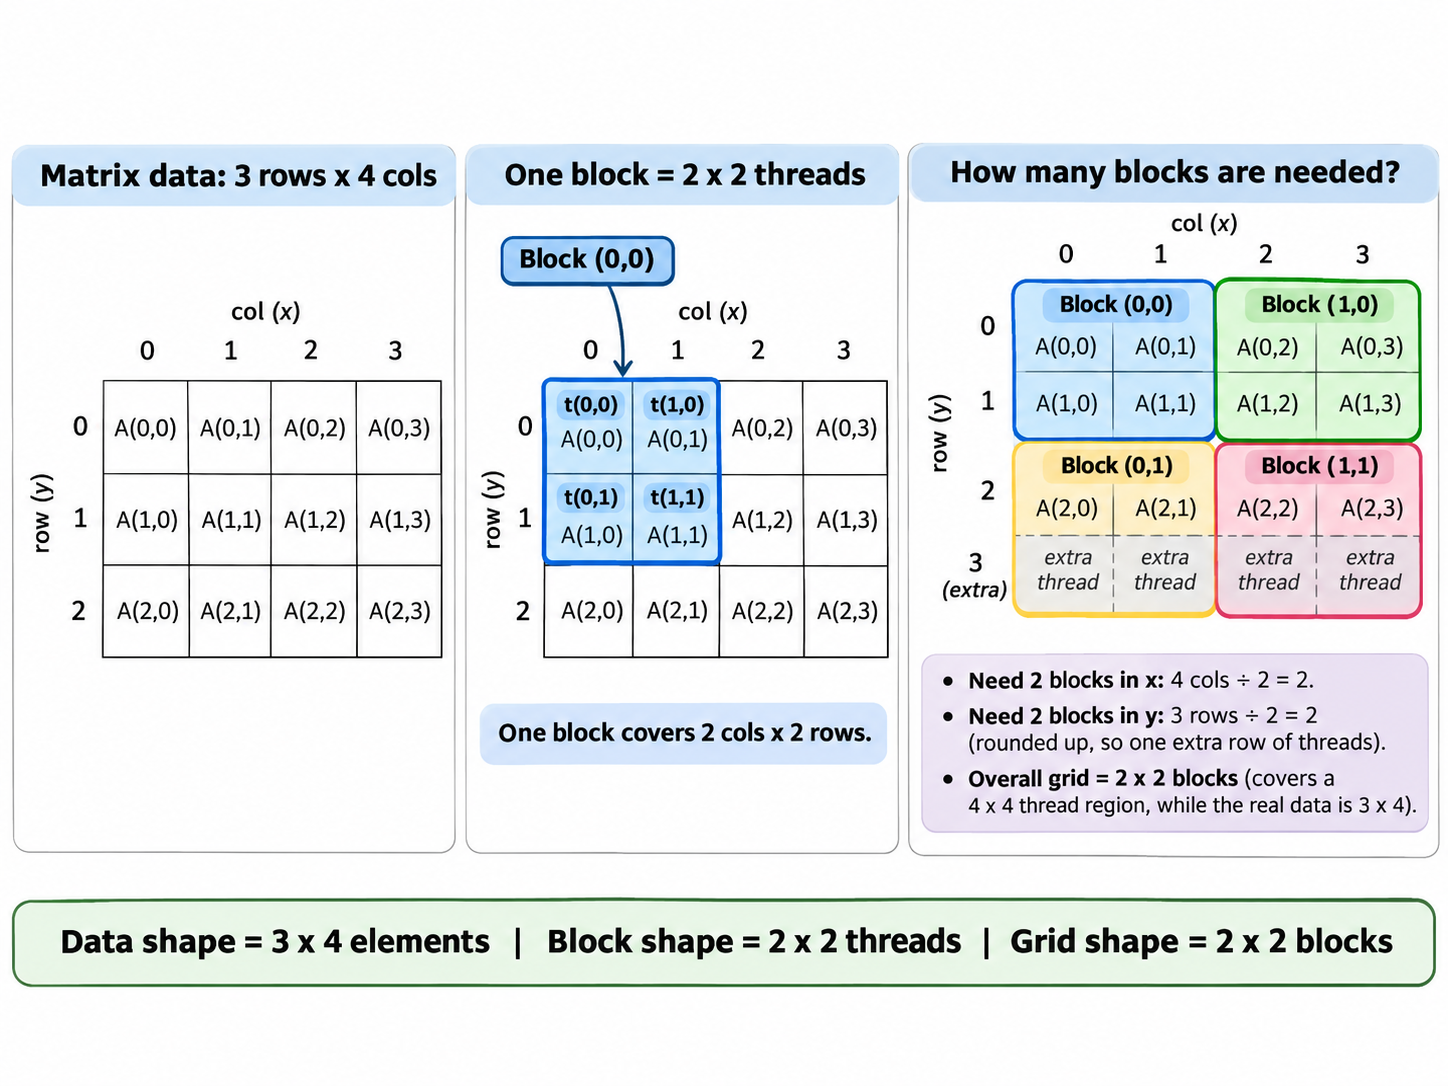

In [ ]:
%%writefile matrix_add_2d.cu

#include <iostream>
#include <vector>
#include <cuda_runtime.h>

__global__ void matrix_add(
    const int* a,
    const int* b,
    int* c,
    int rows,
    int cols
) {
    // Global column
    int col =
        blockIdx.x * blockDim.x
        + threadIdx.x;

    // Global row
    int row =
        blockIdx.y * blockDim.y
        + threadIdx.y;

    // Only valid matrix positions should do work
    if (row < rows && col < cols) {

        // Convert (row, col) -> linear memory index
        int index =
            row * cols + col;

        c[index] =
            a[index] + b[index];
    }
}

int main() {
    const int rows = 3;
    const int cols = 4;

    const int N = rows * cols;
    const size_t bytes = N * sizeof(int);

    // Host matrices stored linearly
    std::vector<int> h_a(N);
    std::vector<int> h_b(N);
    std::vector<int> h_c(N);

    // Initialize A and B
    for (int i = 0; i < N; i++) {
        h_a[i] = i + 1;
        h_b[i] = (i + 1) * 10;
    }

    // Device pointers
    int* d_a;
    int* d_b;
    int* d_c;

    // Allocate GPU memory
    cudaMalloc(&d_a, bytes);
    cudaMalloc(&d_b, bytes);
    cudaMalloc(&d_c, bytes);

    // Copy CPU -> GPU
    cudaMemcpy(
        d_a,
        h_a.data(),
        bytes,
        cudaMemcpyHostToDevice
    );

    cudaMemcpy(
        d_b,
        h_b.data(),
        bytes,
        cudaMemcpyHostToDevice
    );

    // 2 x 2 threads per block
    dim3 threads_per_block(2, 2);

    // Enough blocks to cover all rows and columns
    dim3 blocks(
        (cols + threads_per_block.x - 1)
            / threads_per_block.x,

        (rows + threads_per_block.y - 1)
            / threads_per_block.y
    );

    std::cout
        << "Matrix shape: "
        << rows
        << " x "
        << cols
        << "\n";

    std::cout
        << "Block shape: "
        << threads_per_block.x
        << " x "
        << threads_per_block.y
        << "\n";

    std::cout
        << "Grid shape: "
        << blocks.x
        << " x "
        << blocks.y
        << "\n\n";

    // Launch 2D kernel
    matrix_add<<<blocks, threads_per_block>>>(
        d_a,
        d_b,
        d_c,
        rows,
        cols
    );

    cudaDeviceSynchronize();

    // Copy GPU -> CPU
    cudaMemcpy(
        h_c.data(),
        d_c,
        bytes,
        cudaMemcpyDeviceToHost
    );

    // Print A
    std::cout << "Matrix A:\n";

    for (int row = 0; row < rows; row++) {
        for (int col = 0; col < cols; col++) {

            int index =
                row * cols + col;

            std::cout
                << h_a[index]
                << "\t";
        }

        std::cout << "\n";
    }

    // Print B
    std::cout << "\nMatrix B:\n";

    for (int row = 0; row < rows; row++) {
        for (int col = 0; col < cols; col++) {

            int index =
                row * cols + col;

            std::cout
                << h_b[index]
                << "\t";
        }

        std::cout << "\n";
    }

    // Print C
    std::cout << "\nMatrix C = A + B:\n";

    for (int row = 0; row < rows; row++) {
        for (int col = 0; col < cols; col++) {

            int index =
                row * cols + col;

            std::cout
                << h_c[index]
                << "\t";
        }

        std::cout << "\n";
    }

    // Free GPU memory
    cudaFree(d_a);
    cudaFree(d_b);
    cudaFree(d_c);

    return 0;
}

Overwriting matrix_add_2d.cu


In [ ]:
!nvcc matrix_add_2d.cu -o matrix_add_2d
!./matrix_add_2d

Matrix shape: 3 x 4
Block shape: 2 x 2
Grid shape: 2 x 2

Matrix A:
1	2	3	4	
5	6	7	8	
9	10	11	12	

Matrix B:
10	20	30	40	
50	60	70	80	
90	100	110	120	

Matrix C = A + B:
11	22	33	44	
55	66	77	88	
99	110	121	132	


# 9. Matrix Addition with a 2D CUDA Grid

Now we can combine everything from this note into an actual 2D CUDA kernel.

We will add two matrices:

```text
A

1   2   3   4
5   6   7   8
9  10  11  12
```

and:

```text
B

10   20   30   40
50   60   70   80
90  100  110  120
```

to produce:

```text
C = A + B
```

Each CUDA thread is responsible for one matrix position.

The kernel is:

```cpp
__global__ void matrix_add(
    const int* a,
    const int* b,
    int* c,
    int rows,
    int cols
) {
    int col =
        blockIdx.x * blockDim.x
        + threadIdx.x;

    int row =
        blockIdx.y * blockDim.y
        + threadIdx.y;

    if (row < rows && col < cols) {

        int index =
            row * cols + col;

        c[index] =
            a[index] + b[index];
    }
}
```

---

## Finding the Global Row and Column

The x direction gives us the column:

```cpp
int col =
    blockIdx.x * blockDim.x
    + threadIdx.x;
```

The y direction gives us the row:

```cpp
int row =
    blockIdx.y * blockDim.y
    + threadIdx.y;
```

This is the same global-index idea used in 1D CUDA, except it is now calculated separately in two dimensions.

```text
x direction → column
y direction → row
```

A thread therefore knows which matrix position it belongs to:

```text
(row, col)
```

---

## Checking the Matrix Boundaries

Our grid may contain slightly more threads than there are matrix elements.

So we check:

```cpp
if (row < rows && col < cols)
```

Only threads whose row and column exist inside the matrix are allowed to access memory.

This is the 2D version of:

```cpp
if (i < N)
```

from our earlier 1D kernels.

---

## Converting the 2D Position Into Memory

The thread now knows:

```text
row
column
```

but the matrix is stored linearly in memory.

So we convert:

```text
(row, col)
```

into:

```cpp
int index =
    row * cols + col;
```

For example:

```text
row = 2
col = 1
cols = 4
```

gives:

```text
index = 2 × 4 + 1

index = 9
```

The thread then performs:

```cpp
c[9] = a[9] + b[9];
```

Even though we think of that location as:

```text
C[2][1]
```

the actual memory access uses linear index `9`.

---

# Creating the 2D Block

We use:

```cpp
dim3 threads_per_block(2, 2);
```

This gives every block:

```text
2 threads in x
2 threads in y
```

or:

```text
2 × 2 = 4 threads
```

One block therefore covers a region like:

```text
T T
T T
```

---

# Calculating the 2D Grid

The matrix contains:

```text
4 columns
3 rows
```

Each block covers:

```text
2 columns
2 rows
```

So we calculate the number of blocks separately for each dimension:

```cpp
dim3 blocks(
    (cols + threads_per_block.x - 1)
        / threads_per_block.x,

    (rows + threads_per_block.y - 1)
        / threads_per_block.y
);
```

For the x direction:

```text
(4 + 2 - 1) / 2

= 5 / 2

= 2 blocks
```

For the y direction:

```text
(3 + 2 - 1) / 2

= 4 / 2

= 2 blocks
```

Therefore:

```text
Grid shape = 2 × 2 blocks
```

and:

```text
Block shape = 2 × 2 threads
```

The complete grid launches:

```text
2 × 2 blocks
×
2 × 2 threads per block

= 16 threads
```

The matrix only contains:

```text
3 × 4 = 12 elements
```

so four threads fall outside the real matrix and are ignored by:

```cpp
if (row < rows && col < cols)
```

---

# Complete Mapping

The execution can now be understood as:

```text
2D grid
    ↓
choose block using blockIdx.x / blockIdx.y
    ↓
choose thread inside block using threadIdx.x / threadIdx.y
    ↓
calculate global row and column
    ↓
check matrix boundaries
    ↓
convert (row, col) into linear index
    ↓
perform matrix addition
```

The important kernel pattern is:

```cpp
int col =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int row =
    blockIdx.y * blockDim.y
    + threadIdx.y;

if (row < rows && col < cols) {

    int index =
        row * cols + col;

    c[index] =
        a[index] + b[index];
}
```

This is a standard pattern for mapping CUDA threads onto 2D data such as matrices and images.

In [3]:
%%writefile indexing_3d.cu

#include <cstdio>
#include <cuda_runtime.h>

__global__ void print_3d_indices(
    int width,
    int height,
    int depth
) {
    int x =
        blockIdx.x * blockDim.x
        + threadIdx.x;

    int y =
        blockIdx.y * blockDim.y
        + threadIdx.y;

    int z =
        blockIdx.z * blockDim.z
        + threadIdx.z;

    if (x < width && y < height && z < depth) {

        int index =
            z * width * height
            + y * width
            + x;

        printf(
            "(x=%d, y=%d, z=%d) -> index=%d\n",
            x,
            y,
            z,
            index
        );
    }
}

int main() {

    const int width  = 3;
    const int height = 2;
    const int depth  = 2;

    // 2 x 2 x 2 threads in each block
    dim3 threads_per_block(2, 2, 2);

    // Enough blocks to cover the entire 3D volume
    dim3 blocks(
        (width  + threads_per_block.x - 1)
            / threads_per_block.x,

        (height + threads_per_block.y - 1)
            / threads_per_block.y,

        (depth  + threads_per_block.z - 1)
            / threads_per_block.z
    );

    printf(
        "Volume: %d x %d x %d\n",
        width,
        height,
        depth
    );

    printf(
        "Block: %d x %d x %d threads\n",
        threads_per_block.x,
        threads_per_block.y,
        threads_per_block.z
    );

    printf(
        "Grid: %d x %d x %d blocks\n\n",
        blocks.x,
        blocks.y,
        blocks.z
    );

    print_3d_indices<<<blocks, threads_per_block>>>(
        width,
        height,
        depth
    );

    cudaDeviceSynchronize();

    return 0;
}

Overwriting indexing_3d.cu


In [4]:
!nvcc indexing_3d.cu -o indexing_3d
!./indexing_3d

Volume: 3 x 2 x 2
Block: 2 x 2 x 2 threads
Grid: 2 x 1 x 1 blocks

(x=2, y=0, z=0) -> index=2
(x=2, y=1, z=0) -> index=5
(x=2, y=0, z=1) -> index=8
(x=2, y=1, z=1) -> index=11
(x=0, y=0, z=0) -> index=0
(x=1, y=0, z=0) -> index=1
(x=0, y=1, z=0) -> index=3
(x=1, y=1, z=0) -> index=4
(x=0, y=0, z=1) -> index=6
(x=1, y=0, z=1) -> index=7
(x=0, y=1, z=1) -> index=9
(x=1, y=1, z=1) -> index=10


# 10. 3D CUDA Indexing and Linear Memory

CUDA blocks and grids can also have a third dimension.

For 3D data, each thread can calculate its global `x`, `y`, and `z` coordinates:

```cpp
int x =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int y =
    blockIdx.y * blockDim.y
    + threadIdx.y;

int z =
    blockIdx.z * blockDim.z
    + threadIdx.z;
```

This gives every thread a position inside a 3D volume:

```text
(x, y, z)
```

For example, 3D indexing can be useful for data such as:

```text
volumes
voxels
3D simulations
3D image data
```

---

## Our Example Volume

We use:

```cpp
const int width  = 3;
const int height = 2;
const int depth  = 2;
```

So the volume contains:

```text
3 × 2 × 2 = 12 elements
```

We can imagine it as two 2D layers.

### z = 0

```text
        x

        0   1   2

y = 0   0   1   2
y = 1   3   4   5
```

### z = 1

```text
        x

        0   1   2

y = 0   6   7   8
y = 1   9  10  11
```

Each new `z` value represents another complete 2D layer.

---

## Creating a 3D Block

We use:

```cpp
dim3 threads_per_block(2, 2, 2);
```

This means each block contains:

```text
2 threads in x
2 threads in y
2 threads in z
```

So the total number of threads inside one block is:

```text
2 × 2 × 2 = 8 threads
```

---

## Creating the 3D Grid

The grid is calculated independently for all three dimensions:

```cpp
dim3 blocks(
    (width + threads_per_block.x - 1)
        / threads_per_block.x,

    (height + threads_per_block.y - 1)
        / threads_per_block.y,

    (depth + threads_per_block.z - 1)
        / threads_per_block.z
);
```

For our volume:

```text
width  = 3
height = 2
depth  = 2
```

and block:

```text
2 × 2 × 2
```

the x direction requires:

```text
(3 + 2 - 1) / 2
= 4 / 2
= 2 blocks
```

The y direction requires:

```text
(2 + 2 - 1) / 2
= 3 / 2
= 1 block
```

The z direction requires:

```text
(2 + 2 - 1) / 2
= 3 / 2
= 1 block
```

Therefore:

```text
Grid = 2 × 1 × 1 blocks
```

which matches the program output:

```text
Block: 2 x 2 x 2 threads
Grid: 2 x 1 x 1 blocks
```

---

## Converting `(x, y, z)` Into Linear Memory

Just like our 2D matrix, the 3D volume is still stored linearly in memory.

The linear index is:

```cpp
int index =
    z * width * height
    + y * width
    + x;
```

The three parts have different jobs:

```text
z * width * height
```

skips complete 2D layers.

```text
y * width
```

skips complete rows inside the current layer.

```text
+x
```

moves to the required position inside the row.

So the mental model is:

```text
z → choose layer
y → choose row
x → choose position in row
```

---

## Example

Suppose:

```text
x = 1
y = 1
z = 1
```

with:

```text
width  = 3
height = 2
```

Then:

```text
index =
    z * width * height
    + y * width
    + x
```

becomes:

```text
index =
    1 * 3 * 2
    + 1 * 3
    + 1
```

so:

```text
index =
    6 + 3 + 1
```

and therefore:

```text
index = 10
```

Our kernel confirms this:

```text
(x=1, y=1, z=1) -> index=10
```

Another example:

```text
(x=2, y=1, z=1)
```

gives:

```text
index =
    1 * 3 * 2
    + 1 * 3
    + 2

= 6 + 3 + 2

= 11
```

which also matches the output:

```text
(x=2, y=1, z=1) -> index=11
```

---

## Complete 3D Mapping

The full process is:

```text
3D grid
    ↓
blockIdx.x / blockIdx.y / blockIdx.z
    ↓
threadIdx.x / threadIdx.y / threadIdx.z
    ↓
calculate global x, y, z
    ↓
check volume boundaries
    ↓
convert (x, y, z) into a linear index
    ↓
access the corresponding memory location
```

The core pattern is:

```cpp
int x =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int y =
    blockIdx.y * blockDim.y
    + threadIdx.y;

int z =
    blockIdx.z * blockDim.z
    + threadIdx.z;

if (
    x < width &&
    y < height &&
    z < depth
) {
    int index =
        z * width * height
        + y * width
        + x;
}
```

The printed thread order may appear random because CUDA does not guarantee that blocks or threads execute in numerical order.

What matters is that every valid `(x, y, z)` coordinate maps to the correct linear memory index.

---

# Conclusion

In this note we extended CUDA indexing beyond one dimension.

We learned how CUDA exposes:

```text
threadIdx.x
threadIdx.y
threadIdx.z

blockIdx.x
blockIdx.y
blockIdx.z

blockDim.x
blockDim.y
blockDim.z

gridDim.x
gridDim.y
gridDim.z
```

We used `dim3` to create multidimensional blocks and grids.

For 2D data, we calculated:

```cpp
int col =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int row =
    blockIdx.y * blockDim.y
    + threadIdx.y;
```

and converted the position into linear memory using:

```cpp
int index =
    row * width + col;
```

We then used that mapping to implement a complete 2D matrix-addition kernel.

For 3D data, we calculated:

```cpp
int x =
    blockIdx.x * blockDim.x
    + threadIdx.x;

int y =
    blockIdx.y * blockDim.y
    + threadIdx.y;

int z =
    blockIdx.z * blockDim.z
    + threadIdx.z;
```

and converted the 3D coordinate into linear memory using:

```cpp
int index =
    z * width * height
    + y * width
    + x;
```

The main idea is simple:

```text
1D data → one global index

2D data → row + column
        → linear index

3D data → x + y + z
        → linear index
```

CUDA gives us multidimensional thread coordinates so we can naturally map threads onto the shape of the data we are processing.

This completes **Note 05 — 2D and 3D CUDA Indexing**.